# Lab 1.2 · Analytical SQL with DuckDB

Day 1 · Session 2 · 25 min. What you'll do:
- race a row store against a column store on the same question;
- query CSV and JSON files where they are, and catch a wrong type before it bites;
- answer Finance's question with joins and aggregates, and measure what an inner join loses.

**Tasks**
- [ ] 1 · Race SQLite and DuckDB on one question (5')
- [ ] 2 · Query CSV and JSON files in place (5')
- [ ] 3 · SUMMARIZE a table and catch a wrong type (4')
- [ ] 4 · Join and aggregate: revenue by city (6')
- [ ] 5 · Measure the revenue an inner join loses (5')
- [ ] ✱ Stretch · Find the payments that don't match their order

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # solutions/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import de_utils as U
U.ensure_data()
print("data:", U.RAW, "| quick mode:", U.QUICK)

data: /content/data-engineering/labs\data\raw | quick mode: False


In [2]:
import sqlite3
import duckdb
import de_viz as V

OUT = U.lab_dir("D1_2", reset=True)     # artifacts/D1_2: everything this lab writes
F = OUT.as_posix()
RAW = U.RAW.as_posix()
APP = OUT / "big_app.sqlite"            # a stand-in for a bigger app database
N = U.pick(1_000_000, 200_000)

# One big orders table, built the way the app stores it. Qafila's real table has 45,766 rows, too few to feel the difference.
with duckdb.connect() as build:
    build.sql("SET enable_progress_bar = false")
    build.sql(f"ATTACH '{APP.as_posix()}' AS app (TYPE sqlite)")
    build.sql(f"""
        CREATE TABLE app.orders AS
        SELECT i AS order_id,
               ['RUH-04', 'RUH-05', 'JED-03', 'DMM-01', 'RUH-01'][1 + i % 5] AS store_id,
               strftime(TIMESTAMP '2026-08-01' + to_seconds(i * 5 * 1_000_000 // {N}), '%Y-%m-%d %H:%M:%S') AS created_at,
               round(10 + (hash(i) % 30000) / 100, 2) AS amount,
               CASE WHEN i % 17 = 0 THEN 'cancelled' ELSE 'delivered' END AS status,
               'note from customer ' || (i % 1000) AS note
        FROM range({N}) t(i)""")
print(f"{N:,} orders, {U.size_mb(APP):.0f} MB of SQLite")

1,000,000 orders, 80 MB of SQLite


## 1 · Race SQLite and DuckDB on one question (5')

Finance asks for **revenue per store per day**. SQLite is a **row store** (it keeps each row together on disk), built for an
app's many small writes: the OLTP job. DuckDB is a **column store** (it keeps each column together), built for big reads: the OLAP job.

🤔 **Predict** · The same SQL, the same rows. How much faster is DuckDB? Is its file bigger or smaller than SQLite's?

In [3]:
QUESTION = """
    SELECT substr(created_at, 1, 10) AS day, store_id, round(sum(amount), 2) AS revenue
    FROM orders
    WHERE status = 'delivered'
    GROUP BY 1, 2
    ORDER BY 1, 2"""

times = {}
app = sqlite3.connect(APP)
with U.timer("SQLite (row store)", times):
    answer = app.execute(QUESTION).fetchall()
app.close()

with duckdb.connect(f"{F}/analytics.duckdb") as wh:
    wh.sql("SET enable_progress_bar = false")
    wh.sql(f"ATTACH '{APP.as_posix()}' AS app (TYPE sqlite, READ_ONLY)")
    wh.sql("CREATE OR REPLACE TABLE orders AS FROM app.orders")     # copy once
    wh.sql("DETACH app")
    with U.timer("DuckDB (column store)", times):
        by_duckdb = wh.sql(QUESTION).fetchall()

U.check(by_duckdb == answer, "the same answer from both")
sizes = {"SQLite": U.size_mb(APP), "DuckDB": U.size_mb(OUT / "analytics.duckdb")}
print(f"{times['SQLite (row store)'] / times['DuckDB (column store)']:.0f}x faster | files: SQLite {sizes['SQLite']:.0f} MB, DuckDB {sizes['DuckDB']:.0f} MB")

SQLite (row store)              2146.4 ms


DuckDB (column store)             72.4 ms
✅ the same answer from both
30x faster | files: SQLite 80 MB, DuckDB 13 MB


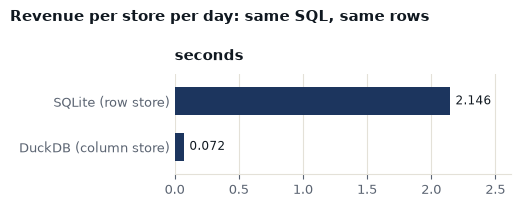

In [4]:
V.bars({"engine": list(times), "seconds": list(times.values())}, "engine", ["seconds"],
       suptitle="Revenue per store per day: same SQL, same rows", fmt="{:.3f}")

🔍 **Look at** both numbers. The question names 4 of the 6 columns, and DuckDB read only those. The `note` column was never touched,
and similar values side by side compress well, so the file is smaller too. Your times will differ; the ratio is the point.

Neither engine is better: SQLite is right for the app's job of saving one order. Ask each to do the other's job and it suffers.

## 2 · Query CSV and JSON files in place (5')

From here on we use Qafila's real data. A file path in `FROM` is a table, and a **glob** (`*`) reads many files at once.

In [5]:
con = duckdb.connect()
con.sql("SET enable_progress_bar = false")
U.attach_app(con)

U.peek(U.RAW / "suppliers" / "prices_2026-W39.csv", 2)
con.sql(f"SELECT column_name, column_type FROM (DESCRIBE FROM read_csv('{RAW}/suppliers/prices_2026-W36.csv'))")

supplier_id,sku,product_name_ar,valid_from,min_order_qty,cost_sar,currency
SUP-FRESHFARMS,QF-FRU-1121,ليمون الواحة حجم عائلي,2026-09-21,48,7.76,SAR


column_nameVARCHAR,column_typeVARCHAR
supplier_id,VARCHAR
sku,VARCHAR
product_name_ar,VARCHAR
unit_cost,DOUBLE
valid_from,DATE
min_order_qty,BIGINT


✏️ **Exercise 1** · The price lists changed columns over the weeks (you saw this in the platform tour). Read all four files as one table
so that no column is lost. Add two options to `read_csv`: `union_by_name = true` matches columns by name across files, and `filename = true` adds the file each row came from.

In [6]:
def all_prices():
    # return con.sql(f"SELECT * FROM read_csv('{RAW}/suppliers/*.csv', all_varchar = true, ___, ___)")
    return con.sql(f"SELECT * FROM read_csv('{RAW}/suppliers/*.csv', all_varchar = true, union_by_name = true, filename = true)")

In [7]:
REF_PRICES = f"SELECT * FROM read_csv('{RAW}/suppliers/*.csv', all_varchar = true, union_by_name = true, filename = true)"
try:
    prices = all_prices()
    U.check({"unit_cost", "cost_sar", "currency", "filename"} <= set(prices.columns), "old and new columns, and the file name, are all there")
except NotImplementedError:
    print("⏭️ Exercise 1 not done yet. Expected: both unit_cost and cost_sar, plus filename. Using the reference result.")
    prices = con.sql(REF_PRICES)
con.sql("SELECT parse_filename(filename) AS file, count(*) AS rows_, count(unit_cost) AS unit_cost, count(cost_sar) AS cost_sar FROM prices GROUP BY ALL ORDER BY file")

✅ old and new columns, and the file name, are all there


fileVARCHAR,rows_BIGINT,unit_costBIGINT,cost_sarBIGINT
prices_2026-W36.csv,160,160,0
prices_2026-W37.csv,160,160,0
prices_2026-W38.csv,160,160,0
prices_2026-W39.csv,160,0,160


🔍 **Look at** the counts: where a week lacks a column, the values are `NULL`. Nothing was thrown away, and every row can be traced to its file.

JSON lines work the same way, with one trap. DuckDB guesses the columns from a sample at the start of the file.
🤔 **Predict** · The payment provider added `wallet_provider` on 15 September. What happens?

In [8]:
try:
    con.sql(f"SELECT * FROM read_json_auto('{RAW}/api/payments.jsonl')").fetchall()
except duckdb.Error as e:
    print("❌ line", str(e).split("in line ")[1].split(":")[0], "has an", str(e)[str(e).find("unknown key"):][:33])

n = con.sql(f"SELECT count(*), count(wallet_provider) FROM read_json_auto('{RAW}/api/payments.jsonl', sample_size = -1)").fetchall()[0]
print(f"✅ with sample_size = -1: {n[0]:,} payments, {n[1]:,} with a wallet_provider")

❌ line 29476 has an unknown key "wallet_provider"
Try


✅ with sample_size = -1: 41,785 payments, 1,102 with a wallet_provider


🔍 A loud error is the good case. `sample_size = -1` reads the whole file before deciding on the columns.

## 3 · SUMMARIZE a table and catch a wrong type (4')

`SUMMARIZE` profiles every column at once: type, min, max, roughly how many distinct values, and how many are null. Run it first on anything new.

In [9]:
con.sql("SELECT column_name, column_type, min, max, approx_unique, null_percentage FROM (SUMMARIZE app.orders)")

column_nameVARCHAR,column_typeVARCHAR,minVARCHAR,maxVARCHAR,approx_uniqueBIGINT,"null_percentageDECIMAL(9,2)"
order_id,BIGINT,5000001,5045766,46544,0.00
customer_id,BIGINT,100000,107586,7124,0.00
store_id,VARCHAR,DMM-01,RUH-06,12,0.00
status,VARCHAR,cancelled,refunded,4,0.00
payment_method,VARCHAR,apple_pay,wallet,4,0.00
promo_code,VARCHAR,FREEDEL,WELCOME10,4,86.46
delivery_fee,DOUBLE,0.0,9.0,2,0.00
created_at,VARCHAR,2026-08-01 02:57:13,2026-09-30 20:57:37,47328,0.00
updated_at,VARCHAR,2026-08-01 03:54:44,2026-09-30 23:59:59,44131,0.00


🔍 `created_at` is `VARCHAR`, text. SQLite has no real timestamp type, so sorting works by luck and date arithmetic fails until you cast it.

A CSV has no types at all: DuckDB **sniffs** them from the values. In week 38 the supplier's Excel wrote decimal commas, and the whole column became text, with no error.

In [10]:
W38 = f"read_csv('{RAW}/suppliers/prices_2026-W38.csv')"
print(con.sql(f"SELECT column_type FROM (DESCRIBE FROM {W38}) WHERE column_name = 'unit_cost'").fetchall()[0][0])
con.sql(f"""
    SELECT count(*) AS price_rows,
           count(TRY_CAST(unit_cost AS DOUBLE)) AS read_as_numbers,
           count(*) - count(TRY_CAST(unit_cost AS DOUBLE)) AS not_numbers,
           min(unit_cost) FILTER (WHERE TRY_CAST(unit_cost AS DOUBLE) IS NULL) AS example
    FROM {W38}""")

VARCHAR


price_rowsBIGINT,read_as_numbersBIGINT,not_numbersBIGINT,exampleVARCHAR
160,0,160,"1,53"


🔍 `TRY_CAST` gives `NULL` where a cast fails, instead of stopping. **Always check the types** before you trust a file. Fixing this column is Lab 3.3's job.

## 4 · Join and aggregate: revenue by city (6')

Revenue isn't stored anywhere. Here it means `quantity * unit_price - discount` on the order lines of **delivered** orders.
The tables you need are `app.orders`, `app.stores` (holds `city`) and `app.order_items`.

✏️ **Exercise 2** · Revenue and order count per city, largest first. The columns: `city`, `orders`, `revenue`.
Hint: an order has several lines, so count it with `count(DISTINCT o.order_id)`. `GROUP BY ALL` groups by everything that isn't aggregated.

In [11]:
def revenue_by_city():
    # return con.sql("""
    #     SELECT s.city, count(DISTINCT o.order_id) AS orders, round(sum(___), 2) AS revenue
    #     FROM app.orders o
    #     JOIN app.stores s USING (store_id)
    #     JOIN app.order_items i USING (___)
    #     WHERE o.status = 'delivered'
    #     GROUP BY ALL ORDER BY revenue DESC""")
    return con.sql("""
        SELECT s.city, count(DISTINCT o.order_id) AS orders, round(sum(i.quantity * i.unit_price - i.discount), 2) AS revenue
        FROM app.orders o
        JOIN app.stores s USING (store_id)
        JOIN app.order_items i USING (order_id)
        WHERE o.status = 'delivered'
        GROUP BY ALL ORDER BY revenue DESC""")

In [12]:
REF_CITY = """
    SELECT s.city, count(DISTINCT o.order_id) AS orders, round(sum(i.quantity * i.unit_price - i.discount), 2) AS revenue
    FROM app.orders o JOIN app.stores s USING (store_id) JOIN app.order_items i USING (order_id)
    WHERE o.status = 'delivered' GROUP BY ALL ORDER BY revenue DESC"""
try:
    by_city = revenue_by_city()
    U.check(by_city.fetchall() == con.sql(REF_CITY).fetchall(), "matches the reference: three cities, 40,419 delivered orders")
except NotImplementedError:
    print("⏭️ Exercise 2 not done yet. Expected: Riyadh, Jeddah, Dammam, 40,419 orders in total. Using the reference result.")
    by_city = con.sql(REF_CITY)
total_revenue = sum(row[2] for row in by_city.fetchall())
print(f"total revenue: {total_revenue:,.2f} SAR")
by_city

✅ matches the reference: three cities, 40,419 delivered orders
total revenue: 6,494,683.83 SAR


cityVARCHAR,ordersBIGINT,revenueDOUBLE
Riyadh,20647,3324639.52
Jeddah,12730,2032240.48
Dammam,7042,1137803.83


🔍 **Look at** the query shape: tables joined on their keys, rows filtered, then grouped. Almost every analytical question is this shape.
Why `count(DISTINCT ...)`? After the join there is one row per line. A plain `count(*)` would count lines and call them orders.

## 5 · Measure the revenue an inner join loses (5')

Marketing wants the same revenue by customer district, so someone adds one more `JOIN app.customers`.
🤔 **Predict** · The numbers still look fine. Does the total change?

In [13]:
inner_revenue = con.sql("""
    SELECT round(sum(i.quantity * i.unit_price - i.discount), 2)
    FROM app.orders o JOIN app.customers c USING (customer_id) JOIN app.order_items i USING (order_id)
    WHERE o.status = 'delivered'""").fetchall()[0][0]
print(f"with the customers join: {inner_revenue:,.2f} SAR | without it: {total_revenue:,.2f} SAR")

with the customers join: 6,349,457.15 SAR | without it: 6,494,683.83 SAR


✏️ **Exercise 3** · Find what went missing: the delivered orders with no row in `app.customers`.
Return one row: `lost_orders` and `lost_revenue`. Hint: `LEFT JOIN` keeps them, and their `c.customer_id` is `NULL`.

In [14]:
def lost_to_inner_join():
    # return con.sql("""
    #     SELECT count(DISTINCT o.order_id) AS lost_orders, round(sum(i.quantity * i.unit_price - i.discount), 2) AS lost_revenue
    #     FROM app.orders o
    #     ___ JOIN app.customers c USING (customer_id)
    #     JOIN app.order_items i USING (order_id)
    #     WHERE o.status = 'delivered' AND ___""").fetchall()[0]
    return con.sql("""
        SELECT count(DISTINCT o.order_id) AS lost_orders, round(sum(i.quantity * i.unit_price - i.discount), 2) AS lost_revenue
        FROM app.orders o
        LEFT JOIN app.customers c USING (customer_id)
        JOIN app.order_items i USING (order_id)
        WHERE o.status = 'delivered' AND c.customer_id IS NULL""").fetchall()[0]

In [15]:
try:
    lost_orders, lost_revenue = lost_to_inner_join()
    U.check(abs(total_revenue - inner_revenue - lost_revenue) < 1, "the lost revenue explains the whole gap")
except NotImplementedError:
    lost_revenue = round(total_revenue - inner_revenue, 2)
    lost_orders = con.sql("""SELECT count(*) FROM app.orders WHERE status = 'delivered'
                             AND customer_id NOT IN (SELECT customer_id FROM app.customers)""").fetchall()[0][0]
    print("⏭️ Exercise 3 not done yet. Using the reference result.")
print(f"lost: {lost_orders:,} delivered orders, {lost_revenue:,.2f} SAR, {lost_revenue / total_revenue:.1%} of revenue")

✅ the lost revenue explains the whole gap
lost: 914 delivered orders, 145,226.68 SAR, 2.2% of revenue


🔍 No error, no warning, and a report that is quietly short. These customers were erased under the PDPL; their orders still happened and still count.
Lab 3.1 keeps these sales with an "unknown customer" row. For now, the habit: **when you add a join, compare the total before and after.**

## ✱ Stretch · Find the payments that don't match their order

Finance checks every captured payment against its order: the lines plus the delivery fee. That check is called **reconciliation**.
Run this and read the differences.

In [16]:
con.sql(f"""
    WITH order_total AS (
        SELECT o.order_id, o.delivery_fee + sum(i.quantity * i.unit_price - i.discount) AS due
        FROM app.orders o JOIN app.order_items i USING (order_id) GROUP BY o.order_id, o.delivery_fee),
    paid AS (
        SELECT order_id, sum(amount) AS paid
        FROM read_json_auto('{RAW}/api/payments.jsonl', sample_size = -1)
        WHERE status = 'captured' GROUP BY ALL)
    SELECT count(*) AS orders_compared,
           count(*) FILTER (WHERE abs(paid - due) > 0.01) AS mismatched,
           round(sum(paid - due) FILTER (WHERE abs(paid - due) > 0.01), 2) AS total_difference
    FROM order_total JOIN paid USING (order_id)""")

orders_comparedBIGINT,mismatchedBIGINT,total_differenceDOUBLE
36468,150,-8.14


## Checkpoint

1. DuckDB answered faster than SQLite from a smaller file. Give the two reasons.
2. A column you expected to be numeric comes out as `VARCHAR`. What do you check first?
3. Adding a join made revenue drop and nothing errored. What happened, and which join keeps the rows?

<details><summary>Answers</summary>

1. It reads only the columns the query names, and similar values stored side by side compress well.
2. Which values won't cast: `TRY_CAST` gives `NULL` for them. A few odd values are enough to turn a whole column into text.
3. An inner join drops rows with no match. `LEFT JOIN` keeps them. Compare the total before and after any join.

</details>

## Carry forward

You can now read any source in place, profile it and answer a question with joins and aggregates. Lab 1.3 adds what `GROUP BY`
can't do: an answer next to every row. It starts from the raw data, so nothing from here is needed.

Want more? `tools/duckdb.ipynb` covers connections, views and the one-writer rule.